In [23]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import mne

## Setup
!!!!
Download from the shared folder:
   - `estimates.pkl`
   - `0_epo.fif`

In the code, change the paths to your documents

## Project pipeline

`estimates` is **not** a predicted EEG. It's the **output of fitting HMP** on the real EEG. My job is to go from it to a predicted EEG.

```
Real EEG (.fif files)
      │
      │  1. HMP fit  ← done by supervisor
      ▼
estimates.pkl  =  WHEN each event happens in each trial (probabilities)
      │
      │  2. predict  ← my job
      ▼
Synthetic EEG  =  bumps placed at those times, with each event's scalp map
      │
      │  3. score  ← my job
      ▼
Compare synthetic EEG vs real EEG  →  a number: how well HMP explains the data
```

## Pipeline: steps

| Step | What | Why |
|---|---|---|
| 1 | **Inspect** channels, metadata and trial numbers | Know what to keep before cutting anything |
| 2 | **Align** EEG with `estimates` | Same trials, channels, time points, sampling rate |
| 3 | Check **RTs match** | Make sure EEG trial *n* = estimates trial *n* |
| 4 | Compute each event's **scalp map** | The "where" ingredient of `predict` |
| 5 | Build the **half-sine** | The "shape" ingredient |
| 6 | **`predict`** (version A: most likely times) | Build the synthetic EEG |
| 7 | **Visual check** | Catch bugs before any metric |
| 8 | **`score`** | Compare synthetic vs real, with baselines |

In [24]:
# Load `estimates.pkl` = the output of the HMP fit
with open("/Users/ella/Desktop/NeuroX/ML/MLProject2/estimation_files/estimates.pkl", "rb") as f:
    estimates = pickle.load(f)

In [25]:
print(estimates)
print(estimates.dims)
print(estimates.shape)
print(list(estimates.coords))

<xarray.DataArray (trial: 28100, sample: 761, event: 4)> Size: 684MB
array([[[0.        , 0.        , 0.        , 0.        ],
        [0.04203548, 0.        , 0.        , 0.        ],
        [0.05621666, 0.        , 0.        , 0.        ],
        ...,
        [0.        , 0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        , 0.        ]],

       [[0.        , 0.        , 0.        , 0.        ],
        [0.05541239, 0.        , 0.        , 0.        ],
        [0.08802668, 0.        , 0.        , 0.        ],
        ...,
        [0.        , 0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        , 0.        ]],

       [[0.        , 0.        , 0.        , 0.        ],
        [0.07522437, 0.        , 0.        , 0.        ],
        [0.11684609, 0.        , 0.        , 0.        ],
        ...,
...
        [0.   

It's an **xarray `DataArray`** of shape **(trial, sample, event) = (28100, 761, 4)**.

| Dimension | Size | Meaning |
|---|---|---|
| `trial` | 28100 | All trials of all participants |
| `sample` | 761 | Time points from stimulus onset, at **256 Hz** (761 samples ≈ 3 s) |
| `event` | 4 | The **4 events** of this model |

- Each value = **probability that an event peaks at a given sample in a given trial** ($p(i,t)$, Eq. 8 / Fig. 1h of Weindel et al., 2024).
- Samples after each trial's RT are **0** (zero-padding).

| Attribute | Value | Meaning |
|---|---|---|
| `sfreq` | 256 | Sampling rate (Hz) |
| `event_width` | 7 | Half-sine width in samples (≈ 27 ms) |
| `trial_lkh` | one value per trial | Log-likelihood of each trial |

| Coordinate (per trial) | Example | Meaning |
|---|---|---|
| `subject` | `'6'` | Participant ID (string) |
| `epoch` | `0` … `1115` | Trial number within a participant |
| `rt` | `0.7383` | Reaction time (seconds) |
| `condition` | `'accuracy'` | Speed vs accuracy instruction |
| `stimulus` | `'59'` | Contrast level (%) |

In [26]:
#only use one participant
subjects = np.unique(estimates["subject"].values)
print(subjects)

one = estimates.isel(trial=(estimates["subject"].values == subjects[0]))
print(one.shape)   # should be ~ (1100, 761, 4)

['0' '1' '10' '11' '12' '13' '14' '15' '16' '17' '18' '19' '2' '20' '21'
 '22' '23' '24' '25' '3' '4' '5' '6' '7' '8' '9']
(1100, 761, 4)


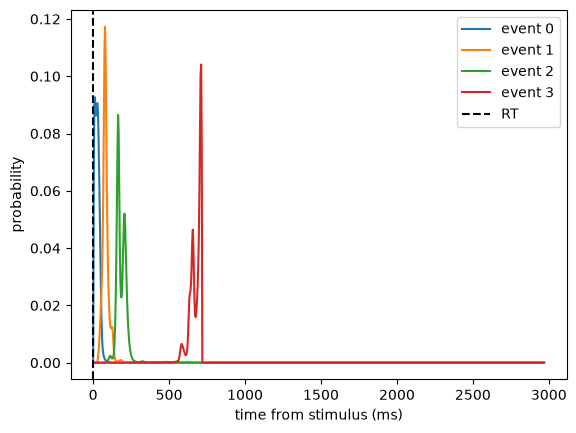

In [27]:
#Plot the probabilities for one trial

trial = one.isel(trial=0)
time_ms = trial["sample"].values / 256 * 1000
for e in range(4):
    plt.plot(time_ms, trial.sel(event=e).values, label=f"event {e}")
plt.axvline(float(trial["rt"].values), color="k", ls="--", label="RT")
plt.xlabel("time from stimulus (ms)")
plt.ylabel("probability")
plt.legend()
plt.show()

In [28]:
#Most likely time of each event in each trial
peak_samples = one.argmax("sample")
print(peak_samples.isel(trial=slice(0, 5)).values)

[[  3  20  42 182]
 [  2  27  64 112]
 [  7  21  42 163]
 [  5  29  40 113]
 [  6  27  49 105]]


In [29]:
# Load the real EEG (one participant)

folder = "/Users/ella/Desktop/NeuroX/ML/MLProject2/"          # your folder path, ending with /
subj = subjects[0]                       # same participant as `one`
epochs = mne.read_epochs(folder + f"{subj}_epo.fif", preload=True)

print(epochs)
print("sfreq:", epochs.info["sfreq"])
print("n trials EEG:", len(epochs), "| n trials estimates:", one.shape[0])
print("n channels:", len(epochs.ch_names))
print("data shape:", epochs.get_data().shape)   # (trials, channels, samples)

Reading /Users/ella/Desktop/NeuroX/ML/MLProject2/0_epo.fif ...
    Found the data of interest:
        t =    -199.22 ...    3000.00 ms
        0 CTF compensation matrices available
Adding metadata with 6 columns
1116 matching events found
No baseline correction applied
0 projection items activated
<EpochsFIF | 1116 events (all good), -0.199 – 3 s (baseline -0.199 – 0 s), ~516.4 MiB, data loaded, with metadata,
 'stimulus/3': 12
 'stimulus/4': 12
 'stimulus/5': 12
 'stimulus/6': 12
 'stimulus/7': 12
 'stimulus/8': 12
 'stimulus/9': 12
 'stimulus/10': 12
 'stimulus/11': 12
 'stimulus/12': 12
 and 83 more events ...>
sfreq: 512.0
n trials EEG: 1116 | n trials estimates: 1100
n channels: 37
data shape: (1116, 37, 1639)


 `_epo` = epochs (EEG already cut into trials). There is **one file per participant**, named `<subject ID>_epo.fif`, matching the `subject` coordinate in `estimates`.

It's an **MNE `Epochs`** object; `epochs.get_data()` has shape **(trials, channels, samples) = (1116, 37, 1639)**.

| Dimension | Size | Meaning |
|---|---|---|
| trials | 1116 | All recorded trials of this participant |
| channels | 37 | 32 EEG electrodes + other channels (e.g. eye electrodes) |
| samples | 1639 | Time points from **−200 ms to 3000 ms** at **512 Hz** (3.2 s × 512) |

- **Epoch window**: −200 ms to 3000 ms around stimulus onset (the 200 ms before the stimulus = baseline).
- **No baseline correction** applied.
- **Metadata** (6 columns): per-trial info (to check, e.g. RT, condition, contrast).
- **Events**: `stimulus/<contrast>`, 12 trials per contrast level (93 levels in total).

#### Mismatches with `estimates` (to fix before comparing)

| | EEG (`epochs`) | `estimates` | Fix |
|---|---|---|---|
| **Sampling rate** | 512 Hz | 256 Hz | Resample EEG to 256 Hz |
| **Trials** | 1116 | 1100 | 16 trials rejected before fitting HMP → keep only the 1100 used (match via `epoch`) |
| **Channels** | 37 | EEG only | Keep EEG channels only |
| **Start of trial** | −200 ms | 0 ms (stimulus) | Cut the baseline |